# 02 - Fine-tuning de CamemBERT sur Allociné (GPU)

Ce notebook entraîne un transformer français (CamemBERT-base, 110 millions de paramètres) sur la
même tâche que la baseline du notebook 01 : classer des critiques de films en positives ou
négatives. Le jeu de données, le découpage et les métriques sont identiques, ce qui rend la
comparaison directe.

Le fine-tuning consiste à partir d'un modèle déjà pré-entraîné sur un très grand corpus de
français, puis à l'ajuster sur la tâche cible avec une petite couche de classification ajoutée
en sortie. Les poids du modèle entier sont mis à jour, avec un taux d'apprentissage faible pour
ne pas détruire ce que le pré-entraînement a appris.

La boucle d'entraînement est écrite explicitement en PyTorch, sans la classe `Trainer` de la
bibliothèque `transformers`. Ce choix rend chaque étape visible (précision mixte, accumulation
des gradients, planification du taux d'apprentissage) et évite toute dépendance à une API de
haut niveau qui évolue d'une version à l'autre.

**Mode d'emploi** : la première exécution se fait avec `SMOKE_TEST = True` (petit sous-ensemble,
une seule epoch) pour vérifier que tout fonctionne et mesurer la vitesse. L'entraînement complet
s'obtient ensuite en passant ce paramètre à `False`.


## 1. Imports et vérification du GPU

In [3]:
# Dépendances (dans l'environnement GPU) :
#   PyTorch avec CUDA : commande générée sur pytorch.org
#   pip install transformers datasets scikit-learn pandas matplotlib tqdm

import copy
import json
import random
import textwrap
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), (
    "Aucun GPU détecté par PyTorch. Lancer check_hardware.py pour identifier la cause "
    "(PyTorch en version CPU, pilote absent ou trop ancien)."
)

device = torch.device("cuda")
gpu_props = torch.cuda.get_device_properties(0)
VRAM_GB = gpu_props.total_memory / 1e9
print(f"GPU : {gpu_props.name} | VRAM : {VRAM_GB:.1f} Go | PyTorch {torch.__version__} (CUDA {torch.version.cuda})")

GPU : NVIDIA GeForce RTX 5070 Ti | VRAM : 17.1 Go | PyTorch 2.14.1+cu132 (CUDA 13.2)


## 2. Configuration

Les hyperparamètres suivent les valeurs usuelles pour le fine-tuning d'un modèle de type BERT :
taux d'apprentissage de l'ordre de 2e-5, un court échauffement (warmup) puis décroissance
linéaire, deux epochs. Au-delà, le gain devient généralement marginal alors que le risque de
sur-apprentissage augmente.

**Précision mixte.** Les calculs sont effectués en 16 bits (au lieu de 32) pour réduire la
mémoire et accélérer l'entraînement. Le format bfloat16 est utilisé sur les GPU récents
(architecture Ampere ou plus, capacité de calcul 8.0+), qui le gèrent nativement. Sur les GPU
plus anciens, le format float16 est utilisé avec une mise à l'échelle de la loss
(`GradScaler`) pour éviter les dépassements de précision.

**Taille de batch.** Elle est déduite de la mémoire vidéo disponible. Elle peut être ajustée
manuellement en cas d'erreur « out of memory ».

In [4]:
# True : exécution rapide de vérification (petit sous-ensemble, 1 epoch).
# False : entraînement complet sur les 160 000 critiques.
SMOKE_TEST = True

MODEL_NAME = "almanach/camembert-base"
MAX_LENGTH = 256          # longueur maximale en tokens ; les textes plus longs sont tronqués
EPOCHS = 2
LEARNING_RATE = 2e-5
WARMUP_RATIO = 0.06       # part des premières étapes consacrée à la montée progressive du LR
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0       # seuil d'écrêtage des gradients, protège contre les instabilités

BATCH_SIZE = 32 if VRAM_GB >= 12 else 16 if VRAM_GB >= 8 else 8

if SMOKE_TEST:
    N_TRAIN, N_VAL, N_TEST, EPOCHS = 2000, 500, 500, 1
    print("MODE TEST RAPIDE : sous-ensemble de données, 1 epoch. Résultats non comparables.")
else:
    N_TRAIN = N_VAL = N_TEST = None

# Précision mixte : bfloat16 nativement sur Ampere+, sinon float16 avec GradScaler
use_bf16 = torch.cuda.get_device_capability(0)[0] >= 8
amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=not use_bf16)
precision_label = "bfloat16" if use_bf16 else "float16 + GradScaler"

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
SAVE_DIR = Path("models") / ("_smoke_test" if SMOKE_TEST else "camembert_allocine")

print(f"Modèle : {MODEL_NAME} | batch : {BATCH_SIZE} | précision : {precision_label}")

MODE TEST RAPIDE : sous-ensemble de données, 1 epoch. Résultats non comparables.
Modèle : almanach/camembert-base | batch : 32 | précision : bfloat16


## 3. Chargement des données

Le découpage officiel (`train`, `validation`, `test`) est conservé, comme dans le notebook 01.

In [5]:
ds = load_dataset("tblard/allocine")


def load_split(name, n):
    df = ds[name].to_pandas()
    if n is not None:
        df = df.sample(n, random_state=SEED)
    return df.reset_index(drop=True)


train_df = load_split("train", N_TRAIN)
val_df = load_split("validation", N_VAL)
test_df = load_split("test", N_TEST)

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:<11} {len(df):>8,} critiques | {df['label'].mean():.1%} positives")

train          2,000 critiques | 50.6% positives
validation       500 critiques | 49.8% positives
test             500 critiques | 47.0% positives


## 4. Tokenisation

Un transformer ne lit pas des mots mais des *tokens* : des fragments de mots issus d'un
vocabulaire fixe (ici SentencePiece, ~32 000 entrées). Un mot rare est découpé en plusieurs
fragments, ce qui permet de traiter n'importe quel texte sans mot « inconnu ».

### Impact de la troncature

Le modèle accepte au plus 512 tokens, et `MAX_LENGTH` est fixé plus bas pour économiser de la
mémoire et du temps. Mesurer la part de critiques réellement tronquées permet de vérifier que ce
choix ne sacrifie pas d'information de façon significative.

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Longueur réelle (sans troncature) mesurée sur un échantillon
sample_texts = train_df["review"].sample(min(3000, len(train_df)), random_state=SEED).tolist()
true_lengths = np.array([len(ids) for ids in tokenizer(sample_texts)["input_ids"]])

print(f"Longueur médiane          : {np.median(true_lengths):.0f} tokens")
print(f"95e percentile            : {np.percentile(true_lengths, 95):.0f} tokens")
print(f"Maximum observé           : {true_lengths.max()} tokens")
print(f"Critiques tronquées à {MAX_LENGTH} : {(true_lengths > MAX_LENGTH).mean():.1%}")

c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\clement\.cache\huggingface\hub\models--almanach--camembert-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Longueur médiane          : 94 tokens
95e percentile            : 344 tokens
Maximum observé           : 502 tokens
Critiques tronquées à 256 : 12.7%


In [7]:
def encode(df):
    # Pas de padding ici : il est appliqué batch par batch (voir DataCollatorWithPadding),
    # ce qui évite de traiter des séquences remplies de zéros inutiles.
    return tokenizer(df["review"].tolist(), truncation=True, max_length=MAX_LENGTH)


start = time.perf_counter()
train_enc, val_enc, test_enc = encode(train_df), encode(val_df), encode(test_df)
print(f"Tokenisation terminée en {time.perf_counter() - start:.1f} s")

Tokenisation terminée en 0.1 s


## 5. Construction des DataLoaders

Le *padding dynamique* aligne les séquences d'un batch sur la plus longue **de ce batch**, et non
sur `MAX_LENGTH`. Comme la plupart des critiques sont courtes, le gain de calcul est important.

Le paramètre `num_workers` reste à 0 : sous Windows, le multiprocessing des DataLoaders dans un
notebook provoque des erreurs, et la tokenisation étant déjà faite, le chargement est rapide.

In [8]:
class EncodedDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": int(self.labels[idx]),
        }


collator = DataCollatorWithPadding(tokenizer)

train_loader = DataLoader(
    EncodedDataset(train_enc, train_df["label"].values),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator,
)
val_loader = DataLoader(
    EncodedDataset(val_enc, val_df["label"].values),
    batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collator,
)
test_loader = DataLoader(
    EncodedDataset(test_enc, test_df["label"].values),
    batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collator,
)

print(f"Étapes par epoch : {len(train_loader):,}")

Étapes par epoch : 63


## 6. Modèle, optimiseur et planification du taux d'apprentissage

`AutoModelForSequenceClassification` charge CamemBERT et ajoute une tête de classification à
deux sorties, initialisée aléatoirement (l'avertissement affiché au chargement est attendu : ces
poids sont justement ceux qui seront appris).

L'optimiseur est AdamW, avec une particularité standard : la régularisation (weight decay) n'est
pas appliquée aux biais ni aux paramètres de normalisation, pour lesquels elle n'a pas de sens.

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Paramètres : {n_params / 1e6:.1f} M")

no_decay = ("bias", "LayerNorm.weight")
param_groups = [
    {
        "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
        "weight_decay": 0.0,
    },
]
optimizer = torch.optim.AdamW(param_groups, lr=LEARNING_RATE)

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(WARMUP_RATIO * total_steps),
    num_training_steps=total_steps,
)

c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\clement\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1242.79it/s]
[transformers] CamembertForSequenceClassification LOAD REPORT from: alm

Paramètres : 110.6 M


## 7. Entraînement

À chaque epoch, le modèle parcourt l'ensemble des données d'entraînement, puis est évalué sur le
jeu de validation. Les poids de la **meilleure** epoch (selon l'accuracy de validation) sont
conservés en mémoire : le dernier état n'est pas nécessairement le meilleur si le modèle
commence à sur-apprendre.

Le jeu de test n'est pas touché ici. Il n'est utilisé qu'une seule fois, à la fin.

In [10]:
@torch.no_grad()
def evaluate(model, loader):
    """Renvoie la loss moyenne, les prédictions, les labels et la probabilité de la classe positive."""
    model.eval()
    total_loss, preds, labels, probs = 0.0, [], [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=amp_dtype):
            out = model(**batch)
        n = batch["labels"].size(0)
        total_loss += out.loss.item() * n
        preds.append(out.logits.argmax(-1).cpu())
        labels.append(batch["labels"].cpu())
        probs.append(torch.softmax(out.logits.float(), dim=-1)[:, 1].cpu())
    labels = torch.cat(labels).numpy()
    return (
        total_loss / len(labels),
        torch.cat(preds).numpy(),
        labels,
        torch.cat(probs).numpy(),
    )


def train_one_epoch(model, loader, epoch):
    model.train()
    running_loss, seen = 0.0, 0
    progress = tqdm(loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False)
    for batch in progress:
        batch = {k: v.to(device) for k, v in batch.items()}

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=amp_dtype):
            loss = model(**batch).loss

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)  # nécessaire avant l'écrêtage des gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        n = batch["labels"].size(0)
        running_loss += loss.item() * n
        seen += n
        progress.set_postfix(loss=f"{running_loss / seen:.4f}")
    return running_loss / seen

In [11]:
history = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time_s": []}
best_val_acc, best_state = 0.0, None

torch.cuda.reset_peak_memory_stats()
train_start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, epoch)
    val_loss, val_preds, val_labels, _ = evaluate(model, val_loader)
    val_acc = accuracy_score(val_labels, val_preds)
    epoch_time = time.perf_counter() - epoch_start

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["epoch_time_s"].append(epoch_time)

    print(f"Epoch {epoch}/{EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} "
          f"| val_acc={val_acc:.4f} | {epoch_time:.0f} s")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

train_time_s = time.perf_counter() - train_start
peak_vram_gb = torch.cuda.max_memory_allocated() / 1e9

print(f"\nEntraînement terminé en {train_time_s / 60:.1f} min | pic de VRAM : {peak_vram_gb:.1f} Go")
if SMOKE_TEST:
    full_epoch_min = history["epoch_time_s"][0] * (160_000 / N_TRAIN) / 60
    print(f"Estimation d'une epoch complète (160 000 critiques) : environ {full_epoch_min:.0f} min")

Epoch 1/1 | train_loss=0.5906 | val_loss=0.4210 | val_acc=0.9060 | 24 s

Entraînement terminé en 0.4 min | pic de VRAM : 5.0 Go
Estimation d'une epoch complète (160 000 critiques) : environ 32 min


### Courbes d'apprentissage

Un écart qui se creuse entre la loss d'entraînement et celle de validation signale du
sur-apprentissage. Avec seulement une ou deux epochs, la courbe contient peu de points : elle
sert surtout à vérifier que la loss décroît.

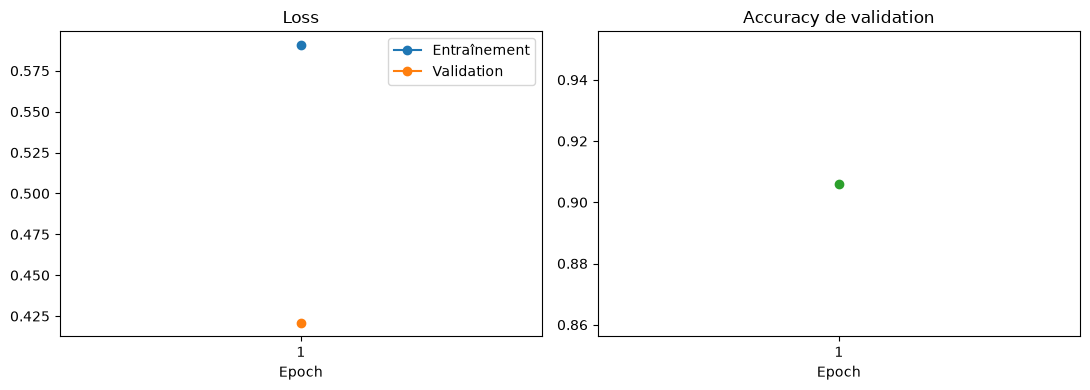

In [12]:
epochs_axis = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs_axis, history["train_loss"], marker="o", label="Entraînement")
axes[0].plot(epochs_axis, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_xticks(list(epochs_axis))
axes[0].legend()

axes[1].plot(epochs_axis, history["val_acc"], marker="o", color="tab:green")
axes[1].set_title("Accuracy de validation")
axes[1].set_xlabel("Epoch")
axes[1].set_xticks(list(epochs_axis))

plt.tight_layout()
plt.show()

## 8. Évaluation finale sur le jeu de test

Les poids de la meilleure epoch sont rechargés, puis le modèle est évalué sur le jeu de test,
jamais utilisé jusqu'ici.

In [13]:
model.load_state_dict(best_state)

_, test_preds, test_labels, test_probs = evaluate(model, test_loader)
accuracy = accuracy_score(test_labels, test_preds)
f1 = f1_score(test_labels, test_preds)

print(f"Accuracy (test) : {accuracy:.4f}")
print(f"F1-score (test) : {f1:.4f}\n")
print(classification_report(test_labels, test_preds, target_names=["négative", "positive"], digits=4))

Accuracy (test) : 0.9400
F1-score (test) : 0.9364

              precision    recall  f1-score   support

    négative     0.9468    0.9396    0.9432       265
    positive     0.9325    0.9404    0.9364       235

    accuracy                         0.9400       500
   macro avg     0.9396    0.9400    0.9398       500
weighted avg     0.9401    0.9400    0.9400       500



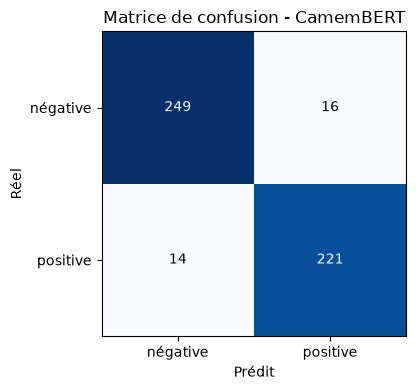

In [14]:
cm = confusion_matrix(test_labels, test_preds)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["négative", "positive"])
ax.set_yticks([0, 1], ["négative", "positive"])
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")
ax.set_title("Matrice de confusion - CamemBERT")

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

## 9. Coût d'inférence

Les mêmes mesures que pour la baseline sont reprises : latence par critique (prédictions
unitaires, comme dans une API), et taille du modèle. La latence est mesurée sur GPU et sur CPU :
le CPU correspond à un déploiement sans carte graphique, et c'est le seul cas directement
comparable à la baseline, mesurée sur CPU.

In [15]:
def measure_latency(model, run_device, reviews, use_autocast):
    model.eval()

    def infer(text):
        enc = tokenizer(text, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(run_device)
        with torch.no_grad():
            if use_autocast:
                with torch.autocast(device_type="cuda", dtype=amp_dtype):
                    return model(**enc).logits.argmax(-1)
            return model(**enc).logits.argmax(-1)

    for text in reviews[:5]:  # échauffement : exclut les coûts d'initialisation
        infer(text)
    if run_device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()
    for text in reviews:
        infer(text)
    if run_device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / len(reviews) * 1000


reviews_sample = test_df["review"].sample(min(200, len(test_df)), random_state=SEED).tolist()

latency_gpu_ms = measure_latency(model, device, reviews_sample, use_autocast=True)
print(f"Latence GPU : {latency_gpu_ms:.1f} ms par critique")

# Mesure CPU : le modèle est déplacé sur CPU (en float32), sur un échantillon réduit car plus lent
model_cpu = copy.deepcopy(model).to("cpu").float()
latency_cpu_ms = measure_latency(model_cpu, torch.device("cpu"), reviews_sample[:50], use_autocast=False)
print(f"Latence CPU : {latency_cpu_ms:.1f} ms par critique")
del model_cpu

Latence GPU : 9.3 ms par critique
Latence CPU : 54.8 ms par critique


## 10. Comparaison avec la baseline

Comparer deux accuracy brutes ne dit pas si l'écart est réel ou dû au hasard de l'échantillon de
test. Le **test de McNemar** répond à cette question pour deux classifieurs évalués sur les mêmes
exemples : il ne considère que les cas où les deux modèles divergent, et teste si l'un a raison
plus souvent que l'autre au-delà de ce que le hasard expliquerait (version exacte, via une loi
binomiale).

La baseline est rechargée depuis le fichier sauvegardé par le notebook 01. Elle doit avoir été
entraînée avec une version de scikit-learn compatible ; en cas d'échec de chargement, cette
section est simplement ignorée.

In [16]:
import joblib

baseline_path = RESULTS_DIR / "baseline_tfidf_logreg.joblib"

try:
    baseline = joblib.load(baseline_path)
    baseline_preds = baseline.predict(test_df["review"])

    base_ok = baseline_preds == test_labels
    bert_ok = test_preds == test_labels

    both_right = int((base_ok & bert_ok).sum())
    only_bert = int((~base_ok & bert_ok).sum())    # baseline se trompe, CamemBERT a raison
    only_base = int((base_ok & ~bert_ok).sum())    # CamemBERT se trompe, baseline a raison
    both_wrong = int((~base_ok & ~bert_ok).sum())

    print(f"Les deux justes        : {both_right:,}")
    print(f"Seul CamemBERT juste   : {only_bert:,}")
    print(f"Seule la baseline juste: {only_base:,}")
    print(f"Les deux se trompent   : {both_wrong:,}")

    n_diff = only_bert + only_base
    if n_diff > 0:
        p_value = binomtest(only_bert, n_diff, 0.5).pvalue
        print(f"\nTest de McNemar exact : p = {p_value:.2e}")
        print("Écart statistiquement significatif (seuil 5 %)." if p_value < 0.05
              else "Écart non significatif : le hasard de l'échantillon peut l'expliquer.")
except Exception as err:
    print(f"Comparaison ignorée : baseline non chargée ({type(err).__name__}: {err})")

c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Les deux justes        : 454
Seul CamemBERT juste   : 16
Seule la baseline juste: 17
Les deux se trompent   : 13

Test de McNemar exact : p = 1.00e+00
Écart non significatif : le hasard de l'échantillon peut l'expliquer.


c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.0 when using version 1.

## 11. Analyse d'erreurs

Les erreurs les plus confiantes de CamemBERT sont à comparer avec celles de la baseline vues dans
le notebook 01 : les deux approches échouent-elles sur les mêmes types de critiques (ironie,
critique nuancée, label discutable), ou sur des cas différents ?

In [17]:
errors = test_df.assign(pred=test_preds, proba_pos=test_probs)
errors = errors[errors["pred"] != errors["label"]].copy()
errors["confidence"] = np.where(errors["pred"] == 1, errors["proba_pos"], 1 - errors["proba_pos"])

print(f"Erreurs totales : {len(errors):,} sur {len(test_df):,} ({len(errors) / len(test_df):.1%})\n")

for _, row in errors.sort_values("confidence", ascending=False).head(5).iterrows():
    truth = "positive" if row["label"] == 1 else "négative"
    print(f"[Réel : {truth} | confiance dans l'erreur : {row['confidence']:.0%}]")
    print(textwrap.fill(row["review"][:500], width=100))
    print("-" * 100)

Erreurs totales : 30 sur 500 (6.0%)

[Réel : positive | confiance dans l'erreur : 73%]
Complètement outrancier, beauf, lamentable... Bref, excellent ! Par contre, à ne pas mettre entre
toutes les mains tant c'est grossier et dégueu à tous les niveaux...
----------------------------------------------------------------------------------------------------
[Réel : positive | confiance dans l'erreur : 72%]
Vu le nombre de mauvaises critiques je m'attendait à un film très moyen voir nul...eh bien pas du
tout ! C'est vraiment pas mal. Bon après c'est sur c'est pas le film le plus effrayant de l'année
mais certaines scènes sont vraiment flippantes (je pense notamment à la fin qui m'a cloué à mon
fauteuil !) Je mets 4 étoiles pour remonter la moyenne injustement basse.
----------------------------------------------------------------------------------------------------
[Réel : positive | confiance dans l'erreur : 70%]
ce qui me fait marrer chez les profils mongoliens d'allociné enfin ceux qui me

## 12. Sauvegarde du modèle et des résultats

Le modèle est sauvegardé au format Hugging Face (`save_pretrained`), rechargeable avec
`from_pretrained`. Il pèse plusieurs centaines de Mo : le dossier `models/` ne doit pas être
versionné sur GitHub (à ajouter au `.gitignore`). Le dépôt sur le Hugging Face Hub, gratuit pour
les modèles, est l'endroit adapté pour le partager.

En mode test rapide, le fichier de résultats est écrit sous un autre nom, afin de ne pas polluer
le tableau comparatif final.

In [18]:
SAVE_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

size_mb = sum(f.stat().st_size for f in SAVE_DIR.rglob("*") if f.is_file()) / 1e6

results = {
    "model": "CamemBERT-base fine-tuné",
    "accuracy": round(accuracy, 4),
    "f1": round(f1, 4),
    "train_time_s": round(train_time_s, 1),
    "latency_ms_gpu": round(latency_gpu_ms, 1),
    "latency_ms_cpu": round(latency_cpu_ms, 1),
    "size_mb": round(size_mb, 1),
    "n_params_m": round(n_params / 1e6, 1),
    "hardware": gpu_props.name,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "max_length": MAX_LENGTH,
    "precision": precision_label,
    "peak_vram_gb": round(peak_vram_gb, 1),
    "smoke_test": SMOKE_TEST,
}

out_name = "camembert_smoke_test.json" if SMOKE_TEST else "camembert.json"
with open(RESULTS_DIR / out_name, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

results

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.22it/s]


{'model': 'CamemBERT-base fine-tuné',
 'accuracy': 0.94,
 'f1': 0.9364,
 'train_time_s': 23.9,
 'latency_ms_gpu': 9.3,
 'latency_ms_cpu': 54.8,
 'size_mb': 444.9,
 'n_params_m': 110.6,
 'hardware': 'NVIDIA GeForce RTX 5070 Ti',
 'epochs': 1,
 'batch_size': 32,
 'max_length': 256,
 'precision': 'bfloat16',
 'peak_vram_gb': 5.0,
 'smoke_test': True}

## Synthèse et suite

Ce notebook produit les chiffres de la deuxième approche : précision, temps d'entraînement,
latence GPU et CPU, taille. Le test de McNemar indique si l'avance sur la baseline est
statistiquement réelle, et l'analyse d'erreurs montre ce que le transformer comprend que le
TF-IDF ne voit pas.

**Notebook 03** : le LLM en few-shot, sans aucun entraînement, évalué sur les mêmes critiques,
puis le tableau comparatif final des trois approches.
